# Comparison: BS vs BUS vs the two BUS→BS ensembles, Walmart and the Favorita hierarchy
Reads the CSVs written by `walmart_cost_ensemble.ipynb` and `stores_cost_ensemble_{daily,monthly,quarterly}.ipynb`.

| method | short description |
|---|---|
| BS | beam search over all conditions (Bart Alg. 1) |
| BUS | plain BUSPaS: closest pairs, all combinations of shared conditions (Alg. 2/3) |
| BUS-α | BUS with α-matrix pairs (§4.3.2) |
| BUS→BS pool | ensemble 1: BUS-α pairs vote for 30 conditions, one beam search over them |
| BUS→BS per-MC | ensemble 2: a small beam search (width 5) per BUS-α mini-cluster over its shared conditions (§4.3.3) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)

DATASETS = ["walmart", "favorita_daily", "favorita_monthly", "favorita_quarterly"]
METHODS = ["BS", "BUS", "BUS-α", "BUS→BS pool", "BUS→BS per-MC"]
main = pd.concat([pd.read_csv(f"results/{d}_main.csv") for d in DATASETS], ignore_index=True)
dfd = pd.concat([pd.read_csv(f"results/{d}_dfd.csv") for d in DATASETS], ignore_index=True)
subgroups = pd.concat([pd.read_csv(f"results/{d}_subgroups.csv") for d in DATASETS], ignore_index=True)
scaling = pd.concat([pd.read_csv(f"results/{d}_scaling.csv") for d in DATASETS], ignore_index=True)

reference = main[(main["method"] == "BS") & (~main["prune"])].set_index(["dataset", "measure"])
for column, source in [("evaluated_vs_BS", "evaluated"), ("generated_vs_BS", "generated"),
                       ("runtime_vs_BS", "runtime_s"), ("max_quality_vs_BS", "max_quality"),
                       ("avg_quality_vs_BS", "avg_quality")]:
    main[column] = [row[source] / reference.loc[(row["dataset"], row["measure"]), source] for _, row in main.iterrows()]

display(main.groupby("dataset", sort=False)[["N", "T", "distance_time_s"]].first().round(3))

,N,T,distance_time_s
dataset,,,
walmart,2566,143,1.334
favorita_daily,1100,910,2.089
favorita_monthly,1100,30,0.059
favorita_quarterly,1100,10,0.023


## 1. Run summary (Bart Table 6.9 + steps), pruned runs
Per dataset and measure: runtime, steps (`generated`, `evaluated` = subgroups checked, `pruned`),
max / average quality and coverage, overlap with unpruned BS and the number of significant subgroups (M2).

In [2]:
significant = (subgroups[(subgroups["measure"] == "M2") & (subgroups["p_value"] < 0.05)]
               .groupby(["dataset", "method"]).size().rename("n_significant"))
summary = main[main["prune"]].merge(significant.reset_index(), on=["dataset", "method"], how="left")
summary.loc[summary["measure"] != "M2", "n_significant"] = np.nan
summary.loc[(summary["measure"] == "M2") & summary["n_significant"].isna(), "n_significant"] = 0
columns = ["runtime_s", "generated", "evaluated", "pruned", "mini_clusters", "mc_spaces", "max_quality",
           "avg_quality", "max_coverage", "avg_coverage", "shared_vs_BS", "pool_recall", "n_significant"]
for dataset in DATASETS:
    print(f"\n=== {dataset} ===")
    display(summary[summary["dataset"] == dataset].set_index(["measure", "method"])[columns].round(3))


=== walmart ===

=== favorita_daily ===

=== favorita_monthly ===

=== favorita_quarterly ===


runtime_s  generated  evaluated  pruned  mini_clusters  mc_spaces   max_quality   avg_quality  max_coverage  avg_coverage  shared_vs_BS  pool_recall  n_significant
measure method                                                                                                                                                                            
M1      BS                 0.579       2467       1848    1403              0        NaN  5.252768e+07  4.224634e+07          0.15         0.127            20          NaN            NaN
        BUS                0.799       3586       2300    1284            200        NaN  5.252768e+07  4.181274e+07          0.15         0.124            19          NaN            NaN
        BUS-α              0.618       3582       2299    1281            200        NaN  5.252768e+07  4.181274e+07          0.15         0.124            19          NaN            NaN
        BUS→BS pool        0.508       1242       1108     605            200        NaN  5.252768e+07  4.003055e+07          0.15         0.120            15        0.882            NaN
        BUS→BS per-MC      1.249       6453       1367    1854            200      157.0  5.252768e+07  4.093021e+07          0.15         0.122            16        1.000            NaN
M2      BS                 0.628       2592       1971    1417              0        NaN  6.350184e+07  4.990778e+07          0.15         0.129            20          NaN            1.0
        BUS                0.537       3586       2306    1278            200        NaN  6.350184e+07  4.929420e+07          0.15         0.127            17          NaN            1.0
        BUS-α              0.647       3582       2305    1275            200        NaN  6.350184e+07  4.929420e+07          0.15         0.127            17          NaN            1.0
        BUS→BS pool        0.493       1249       1144     601            200        NaN  6.350184e+07  4.714807e+07          0.15         0.123            15        0.875            1.0
        BUS→BS per-MC      1.286       6446       1296    1471            200      157.0  6.350184e+07  4.814116e+07          0.15         0.126            15        1.000            1.0
M3      BS                 1.157       2129       1108     322              0        NaN  1.224000e+00  1.168000e+00          0.13         0.079            20          NaN            NaN
        BUS                2.251       8145       5286    1708            200        NaN  1.224000e+00  1.168000e+00          0.13         0.078            19          NaN            NaN
        BUS-α              2.348       8443       5277    1971            200        NaN  1.224000e+00  1.168000e+00          0.13         0.078            19          NaN            NaN
        BUS→BS pool        1.156       1036        661     214            200        NaN  1.224000e+00  1.164000e+00          0.13         0.081            16        0.765            NaN
        BUS→BS per-MC      1.580       4302       1154     652            200       33.0  1.224000e+00  1.167000e+00          0.13         0.077            19        1.000            NaN

runtime_s  generated  evaluated  pruned  mini_clusters  mc_spaces  max_quality  avg_quality  max_coverage  avg_coverage  shared_vs_BS  pool_recall  n_significant
measure method                                                                                                                                                                          
M1      BS                 0.219       1826        649     535              0        NaN  5669723.511  3694255.481         0.118         0.079            20          NaN            NaN
        BUS                0.042        329        231      87            200        NaN  5669723.511  3249768.068         0.147         0.076            10          NaN            NaN
        BUS-α              0.057        329        231      87            200        NaN  5669723.511  3249768.068         0.147         0.076            10          NaN            NaN
        BUS→BS pool        0.152        788        450     339            200        NaN  5669723.511  3414443.354         0.147         0.085            13        0.688            NaN
        BUS→BS per-MC      0.171       1024        236     313            200       83.0  5669723.511  3249768.068         0.147         0.076            10        0.688            NaN
M2      BS                 0.248       2042        715     597              0        NaN  5973673.571  3976943.904         0.131         0.085            20          NaN            0.0
        BUS                0.043        329        231      87            200        NaN  5973673.571  3471804.462         0.148         0.082            10          NaN            0.0
        BUS-α              0.059        329        231      87            200        NaN  5973673.571  3471804.462         0.148         0.082            10          NaN            0.0
        BUS→BS pool        0.155        802        456     345            200        NaN  5973673.571  3673491.767         0.147         0.090            12        0.625            0.0
        BUS→BS per-MC      0.170       1031        237     313            200       83.0  5973673.571  3471804.462         0.148         0.082            10        0.625            0.0
M3      BS                 0.241       1688        494      68              0        NaN        1.695        1.509         0.067         0.035            20          NaN            NaN
        BUS                0.147       1327        593     515            200        NaN        1.695        1.509         0.067         0.034            19          NaN            NaN
        BUS-α              0.186       1780        717     757            200        NaN        1.695        1.505         0.067         0.036            19          NaN            NaN
        BUS→BS pool        0.184        806        334      50            200        NaN        1.695        1.496         0.067         0.034            18        0.933            NaN
        BUS→BS per-MC      0.432       4257        517     386            200      100.0        1.695        1.502         0.067         0.035            18        1.000            NaN

runtime_s  generated  evaluated  pruned  mini_clusters  mc_spaces  max_quality  avg_quality  max_coverage  avg_coverage  shared_vs_BS  pool_recall  n_significant
measure method                                                                                                                                                                          
M1      BS                 0.210       1826        649     535              0        NaN  5669723.511  3694255.481         0.118         0.079            20          NaN            NaN
        BUS                0.047        497        296     184            200        NaN  5669723.511  3416779.150         0.147         0.086            13          NaN            NaN
        BUS-α              0.066        497        296     184            200        NaN  5669723.511  3416779.150         0.147         0.086            13          NaN            NaN
        BUS→BS pool        0.172        941        560     433            200        NaN  5669723.511  3532084.432         0.147         0.089            16        0.875            NaN
        BUS→BS per-MC      0.199       1232        354     420            200      102.0  5669723.511  3416779.150         0.147         0.086            13        1.000            NaN
M2      BS                 0.241       2042        715     597              0        NaN  5973673.571  3976943.904         0.131         0.085            20          NaN            0.0
        BUS                0.053        497        296     184            200        NaN  5973673.571  3741933.772         0.147         0.093            14          NaN            0.0
        BUS-α              0.068        497        296     184            200        NaN  5973673.571  3741933.772         0.147         0.093            14          NaN            0.0
        BUS→BS pool        0.174        941        586     462            200        NaN  5973673.571  3837063.449         0.147         0.093            17        0.875            0.0
        BUS→BS per-MC      0.211       1234        360     421            200      102.0  5973673.571  3741933.772         0.147         0.093            14        1.000            0.0
M3      BS                 0.229       1654        510      86              0        NaN        1.865        1.567         0.146         0.036            20          NaN            NaN
        BUS                0.133       1027        575     304            200        NaN        1.865        1.576         0.146         0.036            18          NaN            NaN
        BUS-α              0.144       1182        503     488            200        NaN        1.865        1.507         0.146         0.058             7          NaN            NaN
        BUS→BS pool        0.177        774        348      21            200        NaN        1.597        1.470         0.146         0.060             5        0.579            NaN
        BUS→BS per-MC      0.273       2404        383     165            200       59.0        1.865        1.492         0.146         0.061             7        0.895            NaN

runtime_s  generated  evaluated  pruned  mini_clusters  mc_spaces  max_quality  avg_quality  max_coverage  avg_coverage  shared_vs_BS  pool_recall  n_significant
measure method                                                                                                                                                                          
M1      BS                 0.300       1826        649     535              0        NaN  5669723.511  3694255.481         0.118         0.079            20          NaN            NaN
        BUS                0.057        571        322     233            200        NaN  5669723.511  3221704.922         0.147         0.094            11          NaN            NaN
        BUS-α              0.095        573        324     233            200        NaN  5669723.511  3221704.922         0.147         0.094            11          NaN            NaN
        BUS→BS pool        0.181        951        553     430            200        NaN  5669723.511  3514457.389         0.147         0.092            15        0.812            NaN
        BUS→BS per-MC      0.248       1474        396     576            200      110.0  5669723.511  3221704.922         0.147         0.094            11        0.875            NaN
M2      BS                 0.248       2042        715     597              0        NaN  5973673.571  3976943.904         0.131         0.085            20          NaN            0.0
        BUS                0.055        571        320     235            200        NaN  5973673.571  3587804.830         0.147         0.100            13          NaN            0.0
        BUS-α              0.076        573        322     235            200        NaN  5973673.571  3587804.830         0.147         0.100            13          NaN            0.0
        BUS→BS pool        0.192        968        584     462            200        NaN  5973673.571  3828463.512         0.147         0.095            16        0.812            0.0
        BUS→BS per-MC      0.267       1486        406     562            200      110.0  5973673.571  3587804.830         0.147         0.100            13        0.875            0.0
M3      BS                 0.243       1693        546      68              0        NaN        1.299        1.107         0.146         0.035            20          NaN            NaN
        BUS                0.136        971        538     306            200        NaN        1.299        1.091         0.146         0.046            14          NaN            NaN
        BUS-α              0.088        607        199     313            200        NaN        1.008        0.833         0.128         0.058             0          NaN            NaN
        BUS→BS pool        0.151        708        222      16            200        NaN        1.216        1.041         0.064         0.033             7        0.611            NaN
        BUS→BS per-MC      0.181       1501        178      54            200       36.0        1.008        0.833         0.128         0.058             0        0.611            NaN

## 2. Do the ensembles beat BS? (ratios to unpruned BS; < 1 = fewer steps / faster)


=== pruning off ===

=== pruning on ===


avg_quality_vs_BS                                       evaluated_vs_BS                                       runtime_vs_BS                                      
method                                    BS   BUS BUS-α BUS→BS pool BUS→BS per-MC              BS   BUS BUS-α BUS→BS pool BUS→BS per-MC            BS   BUS BUS-α BUS→BS pool BUS→BS per-MC
dataset            measure                                                                                                                                                                  
favorita_daily     M1                    1.0  0.88  0.88        0.92          0.88             1.0  0.39  0.39        0.69          0.38           1.0  0.19  0.24        0.57          0.50
                   M2                    1.0  0.87  0.87        0.92          0.87             1.0  0.38  0.38        0.67          0.37           1.0  0.20  0.28        0.65          0.58
                   M3                    1.0  1.00  1.00        0.99          1.00             1.0  1.06  1.28        0.66          1.04           1.0  0.79  1.06        0.77          1.80
favorita_monthly   M1                    1.0  0.92  0.92        0.96          0.92             1.0  0.59  0.59        0.83          0.54           1.0  0.25  0.29        0.63          0.59
                   M2                    1.0  0.94  0.94        0.96          0.94             1.0  0.57  0.57        0.83          0.53           1.0  0.28  0.34        0.73          0.69
                   M3                    1.0  1.01  0.96        0.94          0.95             1.0  1.01  0.88        0.65          0.78           1.0  0.73  0.83        0.78          1.26
favorita_quarterly M1                    1.0  0.87  0.87        0.95          0.87             1.0  0.67  0.67        0.82          0.60           1.0  0.15  0.18        0.34          0.37
                   M2                    1.0  0.90  0.90        0.96          0.90             1.0  0.65  0.65        0.84          0.58           1.0  0.30  0.39        0.77          0.82
                   M3                    1.0  0.99  0.75        0.94          0.75             1.0  0.90  0.33        0.39          0.30           1.0  0.56  0.40        0.52          0.59
walmart            M1                    1.0  0.99  0.99        0.95          0.97             1.0  1.78  1.78        0.58          0.73           1.0  1.27  1.41        0.82          1.83
                   M2                    1.0  0.99  0.99        0.94          0.96             1.0  1.70  1.70        0.57          0.66           1.0  1.21  1.38        0.79          1.73
                   M3                    1.0  1.00  1.00        1.00          1.00             1.0  3.92  3.91        0.65          1.15           1.0  2.20  2.37        1.01          1.44

avg_quality_vs_BS                                       evaluated_vs_BS                                       runtime_vs_BS                                      
method                                    BS   BUS BUS-α BUS→BS pool BUS→BS per-MC              BS   BUS BUS-α BUS→BS pool BUS→BS per-MC            BS   BUS BUS-α BUS→BS pool BUS→BS per-MC
dataset            measure                                                                                                                                                                  
favorita_daily     M1                    1.0  0.88  0.88        0.92          0.88            0.93  0.33  0.33        0.64          0.34          0.85  0.16  0.22        0.59          0.66
                   M2                    1.0  0.87  0.87        0.92          0.87            1.00  0.32  0.32        0.64          0.33          1.09  0.19  0.26        0.68          0.75
                   M3                    1.0  1.00  1.00        0.99          1.00            0.88  1.06  1.28        0.60          0.92          1.03  0.63  0.80        0.79          1.85
favorita_monthly   M1                    1.0  0.92  0.92        0.96          0.92            0.93  0.42  0.42        0.80          0.51          0.79  0.18  0.25        0.65          0.75
                   M2                    1.0  0.94  0.94        0.96          0.94            1.00  0.41  0.41        0.82          0.50          1.06  0.23  0.30        0.77          0.93
                   M3                    1.0  1.01  0.96        0.94          0.95            0.90  1.01  0.88        0.61          0.67          1.07  0.62  0.68        0.83          1.28
favorita_quarterly M1                    1.0  0.87  0.87        0.95          0.87            0.93  0.46  0.46        0.79          0.57          0.59  0.11  0.19        0.35          0.49
                   M2                    1.0  0.90  0.90        0.96          0.90            1.00  0.45  0.45        0.82          0.57          1.08  0.24  0.33        0.83          1.16
                   M3                    1.0  0.99  0.75        0.94          0.75            0.91  0.90  0.33        0.37          0.30          0.87  0.49  0.31        0.54          0.65
walmart            M1                    1.0  0.99  0.99        0.95          0.97            0.94  1.17  1.16        0.56          0.69          1.05  1.45  1.12        0.92          2.27
                   M2                    1.0  0.99  0.99        0.94          0.96            0.95  1.12  1.11        0.55          0.63          1.10  0.94  1.13        0.86          2.25
                   M3                    1.0  1.00  1.00        1.00          1.00            0.82  3.92  3.91        0.49          0.85          1.05  2.04  2.13        1.05          1.43

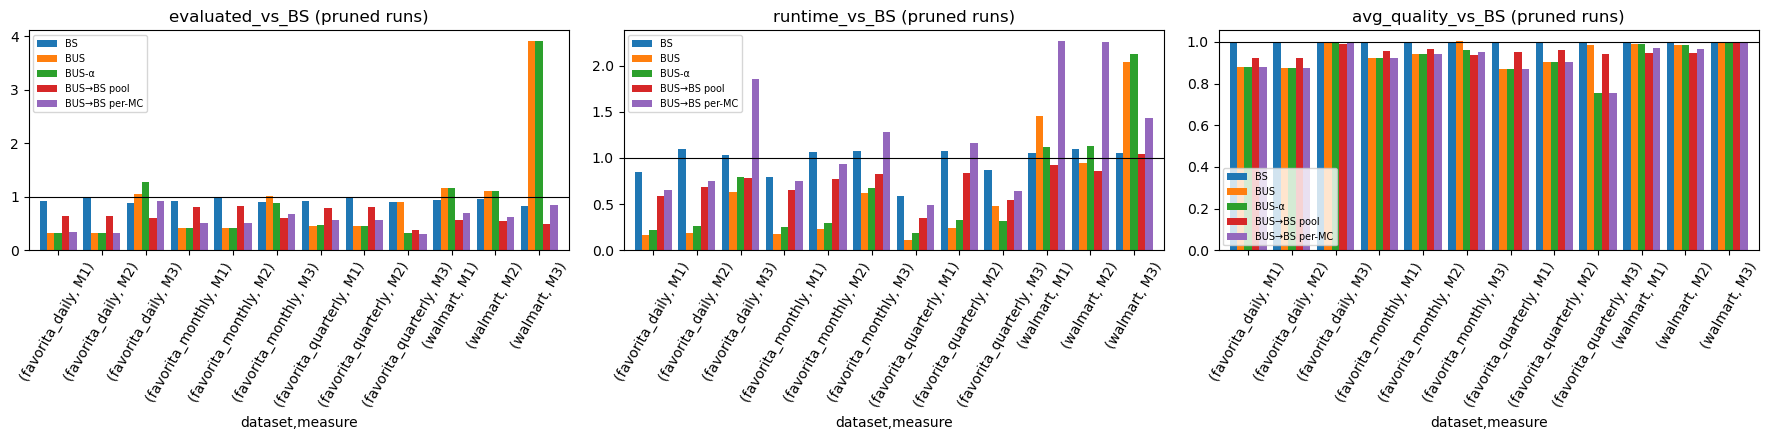

In [3]:
ratio_columns = ["generated_vs_BS", "evaluated_vs_BS", "runtime_vs_BS", "max_quality_vs_BS", "avg_quality_vs_BS",
                 "shared_vs_BS", "pool_recall"]
for prune in (False, True):
    print(f"\n=== pruning {'on' if prune else 'off'} ===")
    table = main[main["prune"] == prune].pivot_table(index=["dataset", "measure"], columns="method",
                                                     values=["evaluated_vs_BS", "runtime_vs_BS", "avg_quality_vs_BS"])
    display(table.reindex(columns=METHODS, level=1).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ["evaluated_vs_BS", "runtime_vs_BS", "avg_quality_vs_BS"]):
    pivot = main[main["prune"]].pivot_table(index=["dataset", "measure"], columns="method", values=metric)[METHODS]
    pivot.plot.bar(ax=ax, rot=60, width=0.85)
    ax.axhline(1, color="black", lw=0.8)
    ax.set_title(f"{metric} (pruned runs)")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 3. The Favorita hierarchy: daily → monthly → quarterly
Same records, descriptors and days; only the target resolution changes. Does the resolution change
the cost (distance matrices, mini-clusters) and the subgroups that are found?

Shared top-20 subgroups between resolutions (out of 20):


,N,T,distance_time_s
dataset,,,
favorita_daily,1100,910,2.089
favorita_monthly,1100,30,0.059
favorita_quarterly,1100,10,0.023


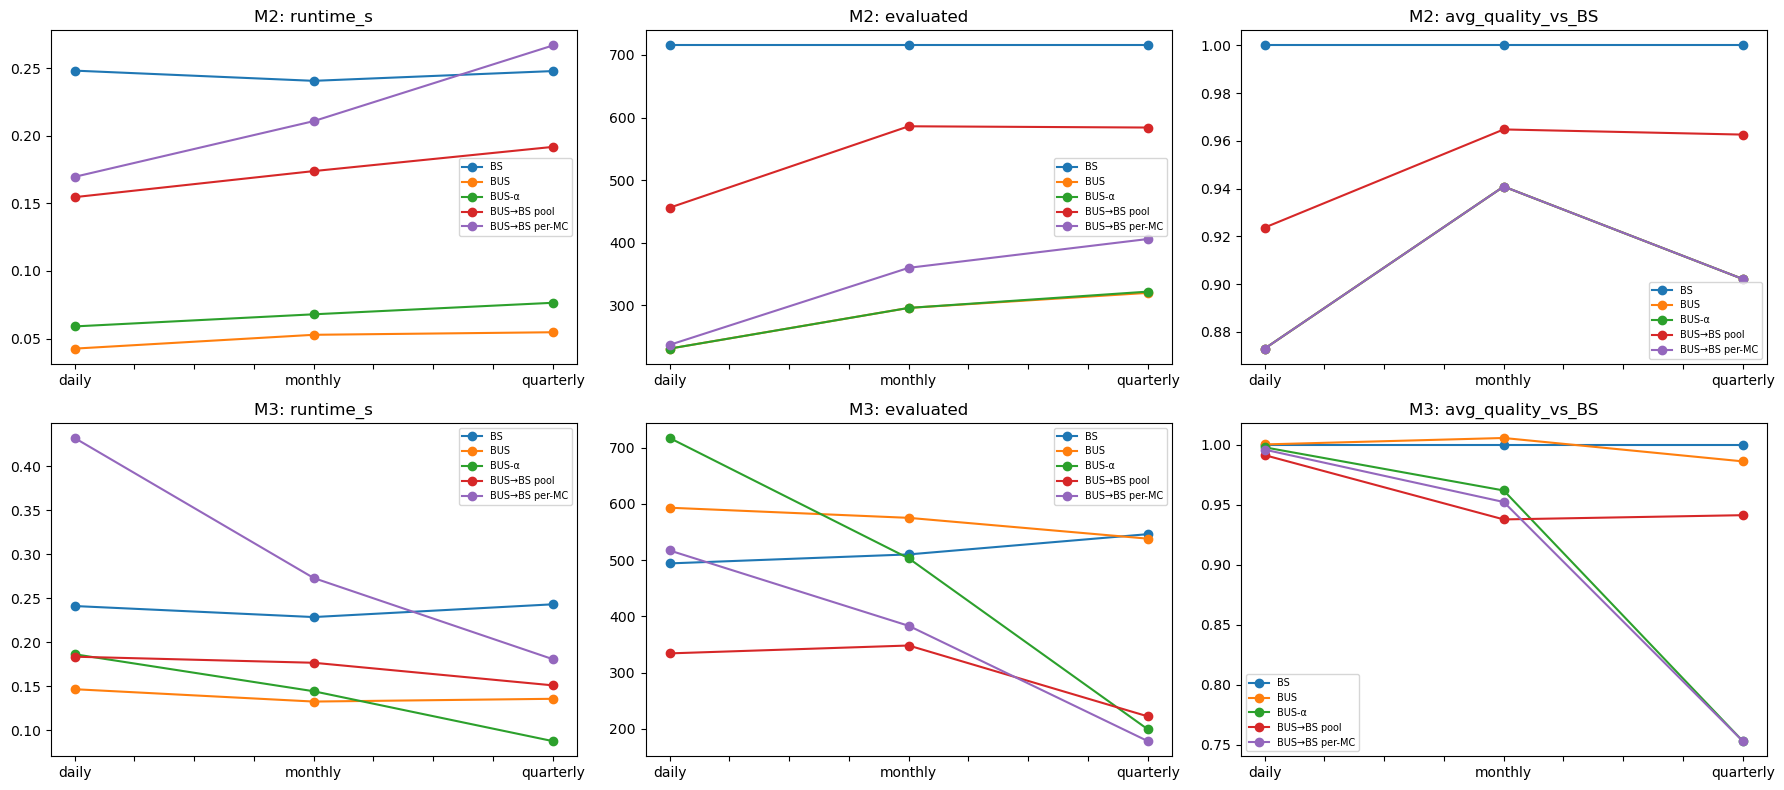

,measure,method,daily∩monthly,daily∩quarterly,monthly∩quarterly,in all three
0,M1,BS,20,20,20,20
1,M1,BUS,9,9,14,8
2,M1,BUS-α,9,9,14,8
3,M1,BUS→BS pool,16,17,19,16
4,M1,BUS→BS per-MC,12,10,15,10
5,M2,BS,20,20,20,20
6,M2,BUS,8,7,15,7
7,M2,BUS-α,8,7,15,7
8,M2,BUS→BS pool,14,15,19,14
9,M2,BUS→BS per-MC,10,8,15,8


In [4]:
hierarchy = ["favorita_daily", "favorita_monthly", "favorita_quarterly"]
h = main[main["dataset"].isin(hierarchy) & main["prune"]]
display(h.groupby("dataset", sort=False)[["N", "T", "distance_time_s"]].first().round(3))

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for row, measure in enumerate(["M2", "M3"]):
    for col, metric in enumerate(["runtime_s", "evaluated", "avg_quality_vs_BS"]):
        ax = axes[row, col]
        pivot = h[h["measure"] == measure].pivot_table(index="dataset", columns="method", values=metric).reindex(hierarchy)[METHODS]
        pivot.index = ["daily", "monthly", "quarterly"]
        pivot.plot(ax=ax, marker="o")
        ax.set_title(f"{measure}: {metric}")
        ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# Do the three resolutions find the same subgroups? (same records, so compare descriptions)
rows = []
for measure in ["M1", "M2", "M3"]:
    for method in METHODS:
        sets = {d: set(subgroups[(subgroups["dataset"] == d) & (subgroups["measure"] == measure)
                                 & (subgroups["method"] == method)]["description"]) for d in hierarchy}
        rows.append({"measure": measure, "method": method,
                     "daily∩monthly": len(sets[hierarchy[0]] & sets[hierarchy[1]]),
                     "daily∩quarterly": len(sets[hierarchy[0]] & sets[hierarchy[2]]),
                     "monthly∩quarterly": len(sets[hierarchy[1]] & sets[hierarchy[2]]),
                     "in all three": len(sets[hierarchy[0]] & sets[hierarchy[1]] & sets[hierarchy[2]])})
print("Shared top-20 subgroups between resolutions (out of 20):")
display(pd.DataFrame(rows))

## 4. Significance (store-level permutation DFD, M2, pruned)

In [5]:
display(dfd.round(3))

,dataset,method,nu,dfd_seconds,dfd_median,dfd_95,best_quality,n_significant_005
0,walmart,BS,100,63.318,4.841174e+07,6.053017e+07,6.350184e+07,1
1,walmart,BUS,100,38.929,4.664079e+07,6.053017e+07,6.350184e+07,1
2,walmart,BUS-α,100,36.064,4.664079e+07,6.053017e+07,6.350184e+07,1
3,walmart,BUS→BS pool,100,38.478,4.615505e+07,5.953493e+07,6.350184e+07,1
4,walmart,BUS→BS per-MC,100,92.441,4.664079e+07,6.053017e+07,6.350184e+07,1
5,favorita_daily,BS,100,22.755,5.938849e+06,8.588459e+06,5.973674e+06,0
6,favorita_daily,BUS,100,4.305,5.006305e+06,8.103672e+06,5.973674e+06,0
7,favorita_daily,BUS-α,100,4.279,5.006305e+06,8.103672e+06,5.973674e+06,0
8,favorita_daily,BUS→BS pool,100,14.582,5.417323e+06,8.208651e+06,5.973674e+06,0
9,favorita_daily,BUS→BS per-MC,100,13.762,5.006305e+06,8.103672e+06,5.973674e+06,0


## 5. The interesting subgroups: top 5 per dataset and method (M2, pruned), all metrics

In [6]:
show = ["rank", "description", "excess_relative", "pct_of_normal", "complement_pct_of_normal", "coverage_n",
        "coverage", "n_stores", "complement_n", "alpha", "beta", "phi_cluster", "lift", "p_value"]
for dataset in DATASETS:
    for method in METHODS:
        table = subgroups[(subgroups["dataset"] == dataset) & (subgroups["measure"] == "M2") & (subgroups["method"] == method)]
        print(f"\n=== {dataset} | {method} ===")
        display(table[show].head(5).round(3))

print("\nAll significant subgroups (p < 0.05), any method:")
display(subgroups[(subgroups["measure"] == "M2") & (subgroups["p_value"] < 0.05)]
        .groupby(["dataset", "description"])
        .agg(methods=("method", lambda s: ", ".join(sorted(set(s)))), p_value=("p_value", "min"),
             excess_relative=("excess_relative", "first"), pct_of_normal=("pct_of_normal", "first"),
             coverage_n=("coverage_n", "first"), n_stores=("n_stores", "first"), lift=("lift", "first"))
        .round(3))


=== walmart | BS ===

=== walmart | BUS ===

=== walmart | BUS-α ===

=== walmart | BUS→BS pool ===

=== walmart | BUS→BS per-MC ===

=== favorita_daily | BS ===

=== favorita_daily | BUS ===

=== favorita_daily | BUS-α ===

=== favorita_daily | BUS→BS pool ===

=== favorita_daily | BUS→BS per-MC ===

=== favorita_monthly | BS ===

=== favorita_monthly | BUS ===

=== favorita_monthly | BUS-α ===

=== favorita_monthly | BUS→BS pool ===

=== favorita_monthly | BUS→BS per-MC ===

=== favorita_quarterly | BS ===

=== favorita_quarterly | BUS ===

=== favorita_quarterly | BUS-α ===

=== favorita_quarterly | BUS→BS pool ===

=== favorita_quarterly | BUS→BS per-MC ===

All significant subgroups (p < 0.05), any method:


,rank,description,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
200,1,Temperature_volatility_cat = medium AND Fuel_Price_volatility_cat = medium AND Unemployment_mean_cat = medium,-6.350184e+07,-4.477,0.935,380,0.148,6,2186,32.167,28.188,1.102,1.161,0.040
201,2,Temperature_slope_cat = medium AND Unemployment_slope_cat = high,-5.953723e+07,-3.965,0.876,381,0.148,6,2185,31.952,28.349,1.089,1.154,0.069
202,3,Temperature_mean_cat = medium AND Unemployment_mean_cat = medium,-5.660969e+07,-4.186,0.832,320,0.125,5,2246,32.068,28.396,1.091,1.152,0.139
203,4,Temperature_mean_cat = medium AND Temperature_volatility_cat = medium AND Unemployment_mean_cat = medium,-5.599170e+07,-5.920,0.823,252,0.098,4,2314,32.693,28.210,1.119,1.160,0.139
204,5,Temperature_mean_cat = medium AND Unemployment_slope_cat = high,-5.527035e+07,-3.587,0.812,383,0.149,6,2183,31.856,28.846,1.067,1.134,0.168


,rank,description,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
220,1,Temperature_volatility_cat = medium AND Fuel_Price_volatility_cat = medium AND Unemployment_mean_cat = medium,-6.350184e+07,-4.477,0.935,380,0.148,6,2186,32.167,28.188,1.102,1.161,0.040
221,2,Temperature_slope_cat = medium AND Unemployment_slope_cat = high,-5.953723e+07,-3.965,0.876,381,0.148,6,2185,31.952,28.349,1.089,1.154,0.069
222,3,Temperature_mean_cat = medium AND Unemployment_mean_cat = medium,-5.660969e+07,-4.186,0.832,320,0.125,5,2246,32.068,28.396,1.091,1.152,0.139
223,4,Temperature_slope_cat = medium AND Temperature_volatility_cat = medium AND Unemployment_slope_cat = high,-5.599170e+07,-5.920,0.823,252,0.098,4,2314,32.693,28.210,1.119,1.160,0.139
224,5,Temperature_mean_cat = medium AND Unemployment_slope_cat = high,-5.527035e+07,-3.587,0.812,383,0.149,6,2183,31.856,28.846,1.067,1.134,0.149


,rank,description,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
240,1,Temperature_volatility_cat = medium AND Fuel_Price_volatility_cat = medium AND Unemployment_mean_cat = medium,-6.350184e+07,-4.477,0.935,380,0.148,6,2186,32.167,28.188,1.102,1.161,0.040
241,2,Temperature_slope_cat = medium AND Unemployment_slope_cat = high,-5.953723e+07,-3.965,0.876,381,0.148,6,2185,31.952,28.349,1.089,1.154,0.069
242,3,Temperature_mean_cat = medium AND Unemployment_mean_cat = medium,-5.660969e+07,-4.186,0.832,320,0.125,5,2246,32.068,28.396,1.091,1.152,0.139
243,4,Temperature_slope_cat = medium AND Temperature_volatility_cat = medium AND Unemployment_slope_cat = high,-5.599170e+07,-5.920,0.823,252,0.098,4,2314,32.693,28.210,1.119,1.160,0.139
244,5,Temperature_mean_cat = medium AND Unemployment_slope_cat = high,-5.527035e+07,-3.587,0.812,383,0.149,6,2183,31.856,28.846,1.067,1.134,0.149


,rank,description,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
260,1,Temperature_volatility_cat = medium AND Fuel_Price_volatility_cat = medium AND Unemployment_mean_cat = medium,-6.350184e+07,-4.477,0.935,380,0.148,6,2186,32.167,28.188,1.102,1.161,0.040
261,2,Temperature_slope_cat = medium AND Unemployment_slope_cat = high,-5.953723e+07,-3.965,0.876,381,0.148,6,2185,31.952,28.349,1.089,1.154,0.059
262,3,Temperature_volatility_cat = medium AND Unemployment_mean_cat = medium AND Unemployment_slope_cat = high,-5.599170e+07,-5.920,0.823,252,0.098,4,2314,32.693,28.210,1.119,1.160,0.119
263,4,Temperature_volatility_cat = medium AND Unemployment_slope_cat = high,-5.470816e+07,-4.902,0.804,315,0.123,5,2251,32.264,29.112,1.071,1.124,0.158
264,5,Fuel_Price_slope_cat = high AND CPI_slope_cat = low AND Unemployment_volatility_cat = medium,-5.400519e+07,-4.481,0.793,375,0.146,6,2191,32.649,29.472,1.071,1.110,0.168


...

,rank,description,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
1120,1,transactions_mean_cat = low AND transactions_slope_cat = high,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.356
1121,2,transactions_slope_cat = high AND transactions_volatility_cat = medium,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.564
1122,3,type = D AND transactions_slope_cat = high,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.842
1123,4,transactions_slope_cat = very_high,4103737.226,5.045,-0.724,91,0.083,4,1009,2.873,2.187,0.901,1.408,0.881
1124,5,promo_slope_vs_peers_cat = very_high,3996420.588,5.361,-0.706,89,0.081,21,1011,5.065,6.345,0.690,0.485,0.911


,rank,description,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
1140,1,transactions_mean_cat = low AND transactions_slope_cat = high,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.356
1141,2,transactions_slope_cat = high AND transactions_volatility_cat = medium,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.564
1142,3,type = D AND transactions_slope_cat = high,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.842
1143,4,transactions_slope_cat = very_high,4103737.226,5.045,-0.724,91,0.083,4,1009,2.873,2.187,0.901,1.408,0.881
1144,5,promo_slope_vs_peers_cat = very_high,3996420.588,5.361,-0.706,89,0.081,21,1011,5.065,6.345,0.690,0.485,0.911


,rank,description,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
1160,1,transactions_mean_cat = low AND transactions_slope_cat = high,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.396
1161,2,type = D AND transactions_mean_cat = low,5660098.435,15.045,-0.983,115,0.105,6,985,4.396,5.412,0.686,0.569,0.475
1162,3,transactions_slope_cat = high AND transactions_volatility_cat = medium,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.673
1163,4,type = D AND transactions_slope_cat = high,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.891
1164,5,transactions_mean_cat = low AND promo_slope_vs_peers_cat = medium,4170064.724,8.485,-0.735,130,0.118,22,970,4.069,5.158,0.661,0.597,0.921


,rank,description,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
1180,1,transactions_mean_cat = low AND transactions_slope_cat = high,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.356
1181,2,transactions_slope_cat = high AND transactions_volatility_cat = medium,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.564
1182,3,type = D AND transactions_slope_cat = high,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.842
1183,4,transactions_slope_cat = very_high,4103737.226,5.045,-0.724,91,0.083,4,1009,2.873,2.187,0.901,1.408,0.881
1184,5,promo_slope_vs_peers_cat = very_high,3996420.588,5.361,-0.706,89,0.081,21,1011,5.065,6.345,0.690,0.485,0.911


,,methods,p_value,excess_relative,pct_of_normal,coverage_n,n_stores,lift
dataset,description,,,,,,,
walmart,Temperature_volatility_cat = medium AND Fuel_Price_volatility_cat = medium AND Unemployment_mean_cat = medium,"BS, BUS, BUS-α, BUS→BS per-MC, BUS→BS pool",0.04,-6.350184e+07,-4.477,380,6,1.161


## 6. What does pruning buy?

In [7]:
pivot = main.pivot_table(index=["dataset", "measure", "method"], columns="prune",
                         values=["evaluated", "runtime_s", "max_quality", "avg_quality"])
pruning = pd.DataFrame({
    "evaluated_saved_%": 100 * (1 - pivot[("evaluated", True)] / pivot[("evaluated", False)]),
    "runtime_saved_%": 100 * (1 - pivot[("runtime_s", True)] / pivot[("runtime_s", False)]),
    "max_quality_change_%": 100 * (pivot[("max_quality", True)] / pivot[("max_quality", False)] - 1),
    "avg_quality_change_%": 100 * (pivot[("avg_quality", True)] / pivot[("avg_quality", False)] - 1),
})
display(pruning.round(1))

evaluated_saved_%  runtime_saved_%  max_quality_change_%  avg_quality_change_%
dataset            measure method                                                                                       
favorita_daily     M1      BS                           7.0             15.4                   0.0                   0.0
                           BUS                         15.1             13.0                   0.0                   0.0
                           BUS-α                       15.1              6.9                   0.0                   0.0
                           BUS→BS per-MC                9.9            -32.3                   0.0                   0.0
                           BUS→BS pool                  6.4             -2.0                   0.0                   0.0
                   M2      BS                           0.0             -9.4                   0.0                   0.0
                           BUS                         15.1              6.1                   0.0                   0.0
                           BUS-α                       15.1              6.3                   0.0                   0.0
                           BUS→BS per-MC                9.5            -28.4                   0.0                   0.0
                           BUS→BS pool                  5.0             -4.4                   0.0                   0.0
                   M3      BS                          11.9             -3.3                   0.0                   0.0
                           BUS                          0.0             20.2                   0.0                   0.0
                           BUS-α                        0.0             24.4                   0.0                   0.0
                           BUS→BS per-MC               11.6             -2.8                   0.0                   0.0
                           BUS→BS pool                 10.5             -2.2                   0.0                   0.0
favorita_monthly   M1      BS                           7.0             21.0                   0.0                   0.0
                           BUS                         28.0             28.6                   0.0                   0.0
                           BUS-α                       28.0             14.6                   0.0                   0.0
                           BUS→BS per-MC                6.6            -26.8                   0.0                   0.0
                           BUS→BS pool                  3.1             -3.7                   0.0                   0.0
                   M2      BS                           0.0             -6.3                   0.0                   0.0
                           BUS                         28.0             17.0                   0.0                   0.0
                           BUS-α                       28.0             12.6                   0.0                   0.0
                           BUS→BS per-MC                4.8            -35.3                   0.0                   0.0
                           BUS→BS pool                  1.7             -5.6                   0.0                   0.0
                   M3      BS                          10.4             -7.3                   0.0                   0.0
                           BUS                          0.0             14.3                   0.0                   0.0
                           BUS-α                        0.0             18.0                   0.0                   0.0
                           BUS→BS per-MC               13.3             -1.7                   0.0                   0.0
                           BUS→BS pool                  5.7             -5.9                   0.0                   0.0
favorita_quarterly M1      BS                           7.0             41.4                   0.0                   0.0
                           BUS                   

## 7. Scaling with the number of records (pruned runs, mean over seeds)

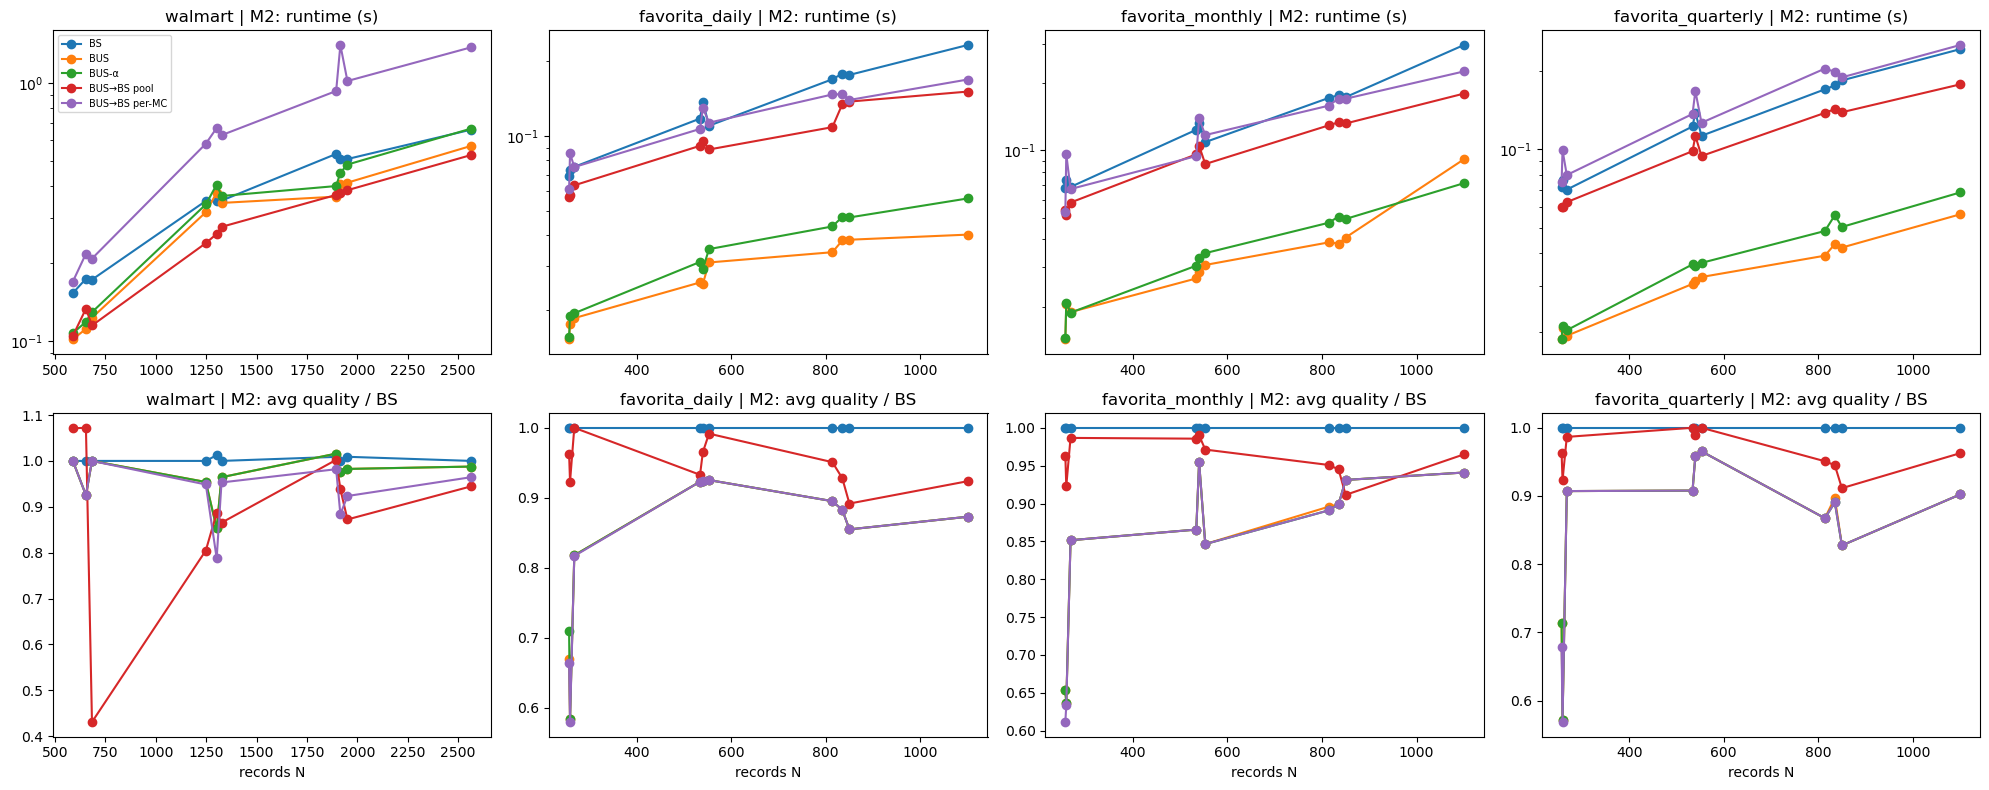

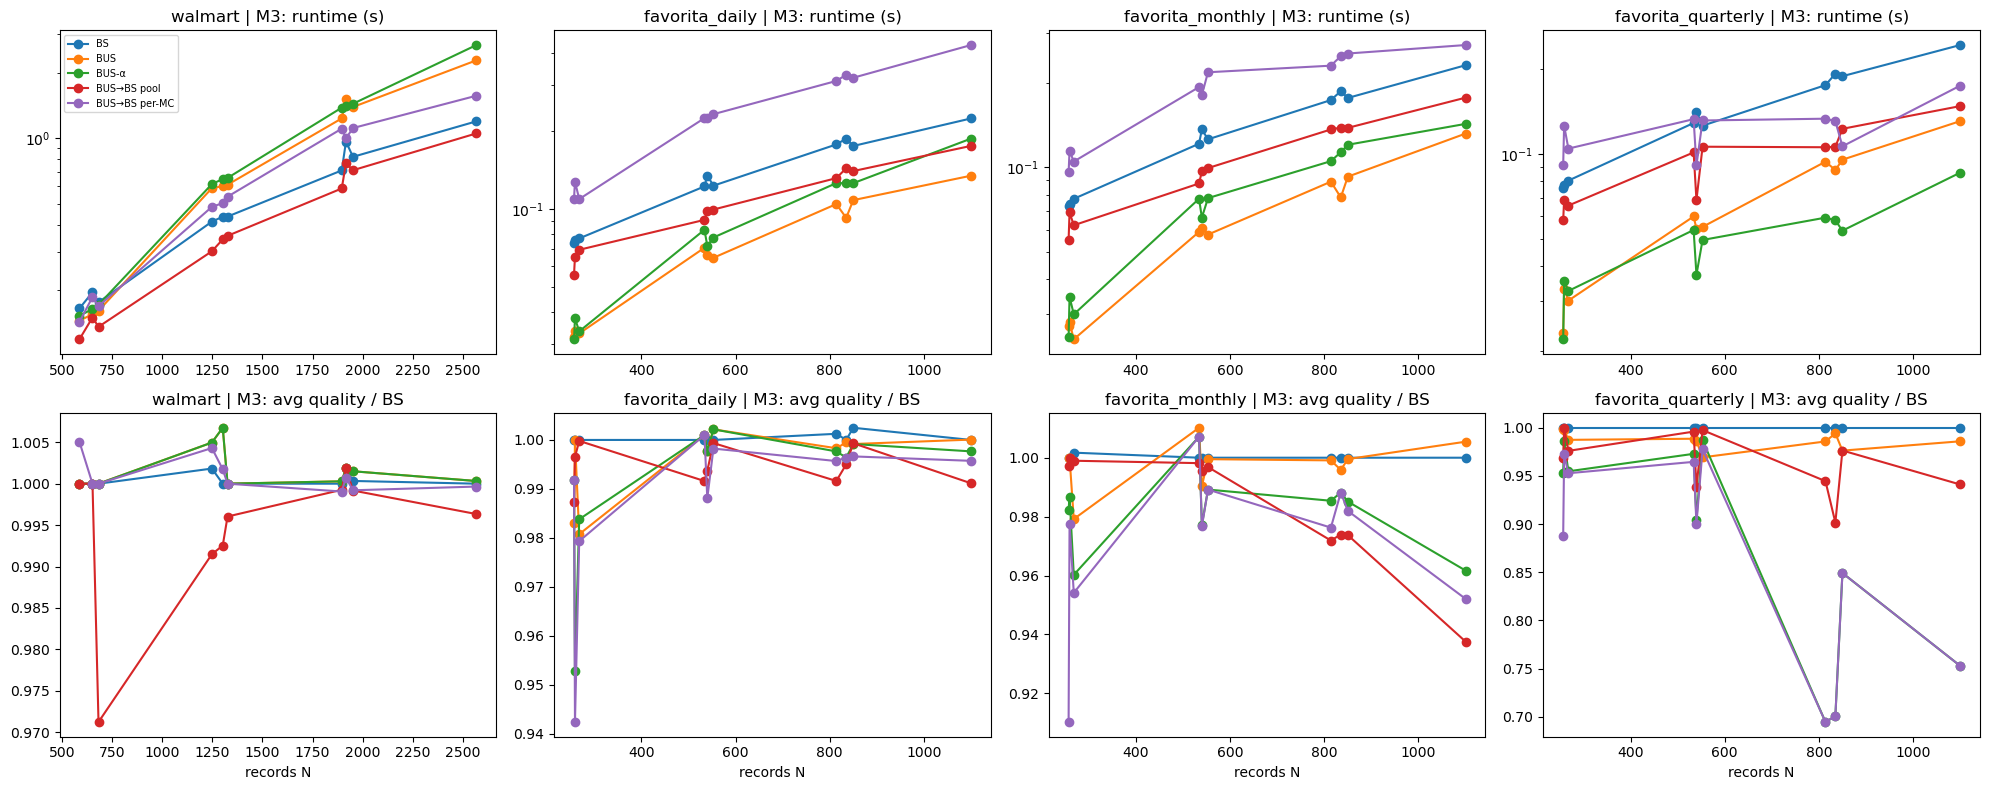

N_sub  runtime_s  evaluated  best_vs_BS  avg_vs_BS  jaccard_vs_BS
dataset            measure method        fraction                                                                      
walmart            M2      BS            0.25       641.333      0.167    496.667       1.000      1.000          1.000
                           BUS           0.25       641.333      0.112   1184.333       1.000      0.975          0.952
                           BUS-α         0.25       641.333      0.118   1184.333       1.000      0.975          0.952
                           BUS→BS pool   0.25       641.333      0.118    431.000       0.758      0.858          0.656
                           BUS→BS per-MC 0.25       641.333      0.199    466.333       1.000      0.975          0.952
...                                                     ...        ...        ...         ...        ...            ...
favorita_quarterly M3      BS            1.00      1100.000      0.243    546.000       1.000      1.000          1.000
                           BUS           1.00      1100.000      0.131    538.000       1.000      0.986          0.538
                           BUS-α         1.00      1100.000      0.086    199.000       0.776      0.753          0.000
                           BUS→BS pool   1.00      1100.000      0.148    222.000       0.936      0.941          0.212
                           BUS→BS per-MC 1.00      1100.000      0.175    178.000       0.776      0.753          0.000

[160 rows x 6 columns]

In [8]:
for measure in ["M2", "M3"]:
    fig, axes = plt.subplots(2, len(DATASETS), figsize=(5 * len(DATASETS), 8))
    for col, dataset in enumerate(DATASETS):
        sub = scaling[(scaling["dataset"] == dataset) & (scaling["measure"] == measure) & scaling["prune"]]
        agg = sub.groupby(["method", "N_sub"])[["runtime_s", "avg_vs_BS"]].mean().reset_index()
        for method in METHODS:
            g = agg[agg["method"] == method]
            axes[0, col].plot(g["N_sub"], g["runtime_s"], marker="o", label=method)
            axes[1, col].plot(g["N_sub"], g["avg_vs_BS"], marker="o", label=method)
        axes[0, col].set_title(f"{dataset} | {measure}: runtime (s)")
        axes[0, col].set_yscale("log")
        axes[1, col].set_title(f"{dataset} | {measure}: avg quality / BS")
        axes[1, col].set_xlabel("records N")
    axes[0, 0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

display(scaling[scaling["prune"]].groupby(["dataset", "measure", "method", "fraction"], sort=False)[
    ["N_sub", "runtime_s", "evaluated", "best_vs_BS", "avg_vs_BS", "jaccard_vs_BS"]].mean().round(3))

## Conclusions (full run: ν = 100, 4 store fractions × 3 seeds)
**Ensemble 2, BUS→BS per-MC (beam search per mini-cluster, Bart §4.3.3)**
- Fewer *unique* evaluations than BS everywhere: Walmart 0.63–0.86×, Favorita 0.30–0.92×. Same best subgroup on the full data in every case except Favorita quarterly M3.
- But on Walmart it is **slower** than BS (1.4–2.3×). Its 157 mini-cluster searches revisit the same descriptions (visits ≈ 6,200 vs 1,300 unique). Store-level descriptors give every same-store pair the same 15 shared conditions, and similar stores give heavily overlapping sets.
- On Favorita the mini-cluster condition sets are small, so a width-5 beam already covers almost all of them. It returns exactly BUS's subgroups (same quality, same overlap), at 2–4× BUS's runtime.
- It is the most robust ensemble on small Walmart subsets (best = BS at 25% of stores, where the pool ensemble reaches only 0.76×), because it never drops a condition.

**Ensemble 1, BUS→BS pool**: 0.37–0.84× BS's evaluations and 0.36–1.05× its runtime, average top-20 quality 0.92–1.0× (worse only for Favorita monthly/quarterly M3). Overall the best speed/quality trade-off.

**Favorita hierarchy (daily T = 910 → monthly 30 → quarterly 10, same 1,100 records)**
- M1/M2 are resolution-invariant by construction: summed expected sales don't depend on how the days are grouped. So BS finds the identical 20 subgroups at all three levels. Only the BUS-type methods change, because their mini-clusters come from distance matrices that do depend on resolution.
- M3 (shape of the deviation) changes a lot: BS shares only 5 of 20 subgroups between daily and quarterly. BUS-α and per-MC fail at quarterly M3 (best 0.78× BS): with 10 points, the α-pairs pick unrepresentative records.
- The cost of resolution is only the distance matrices (2.1 s daily → 0.06 s monthly → 0.02 s quarterly). Search runtimes barely change.

**Significance and the subgroups.** Walmart: one subgroup is significant, and all five methods find it: Temperature volatility = medium ∧ Fuel price volatility = medium ∧ Unemployment mean = medium, −$63.5M relative excess (−4.5% of normal vs +0.9% in the complement), 380 records / 6 stores, lift 1.16, φ 1.10, p = 0.04. Favorita: nothing significant at any resolution (p ≥ 0.4). Its top subgroups also have lift < 1, so the money effect comes from a few records, not a shared pattern.
